<a href="https://colab.research.google.com/github/Prateek-Dhar-Dwivedi/NLP_Practical_2026_Colab_Files/blob/main/Practical_6_Breast_Cancer_Classifier_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical 6: Classifier Evaluation Lab
## Precision, Recall, F1-Score, Confusion Matrix, Macro vs Weighted Average

**Project:** Evaluate classifiers on the Breast Cancer Wisconsin diagnostic dataset.  
**Goal:** Understand why accuracy alone can be misleading and learn to compare models using classification metrics.

### Learning outcomes
- Calculate accuracy, precision, recall, and F1-score.
- Read a confusion matrix.
- Compare Naive Bayes with Logistic Regression.
- Understand macro and weighted averaging in a multi-class setting.

**How to use:** Run each cell from top to bottom. This notebook is self-contained and creates its own demonstration dataset.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

sns.set_theme(style='whitegrid')
print('Libraries imported successfully.')

Libraries imported successfully.


## 2. Create an imbalanced dataset
We use scikit-learn's Breast Cancer Wisconsin diagnostic dataset. Class `0` means **malignant** and class `1` means **benign**. This dataset has an unequal class distribution, making it useful for discussing why accuracy is not enough. This is a learning exercise, not a medical diagnostic tool.

In [2]:
from sklearn.datasets import load_breast_cancer

# Scikit-learn dataset: 569 samples, 30 numeric diagnostic features.
# Original target: 0 = malignant, 1 = benign.
cancer = load_breast_cancer()
X = cancer.data
y = (cancer.target == 1).astype(int)  # 0 = malignant (positive class), 1 = benign

feature_names = list(cancer.feature_names)
df = pd.DataFrame(X, columns=feature_names)
df['label'] = np.where(y == 0, 0, 1)
df['label_name'] = pd.Series(y).map({0: 'Malignant', 1: 'Benign'})

display(df.head())
print('Class counts:')
display(df['label_name'].value_counts().rename_axis('Class').to_frame('Count'))
print(f"Malignant prevalence: {100 * np.mean(y == 0):.2f}%")


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,label,label_name
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


Class counts:


,Count
Class,
Benign,357
Malignant,212


Malignant prevalence: 37.26%


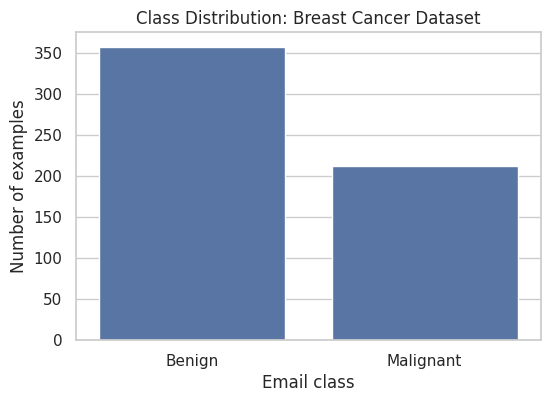

In [3]:
counts = df['label_name'].value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.title('Class Distribution: Breast Cancer Dataset')
plt.xlabel('Email class')
plt.ylabel('Number of examples')
plt.show()

## 3. Split data and train two classifiers
We compare two models: Gaussian Naive Bayes and Logistic Regression. A stratified split preserves the approximate class proportions.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

models = {
    'Naive Bayes': GaussianNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight=None)
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f'{name}: trained')

Naive Bayes: trained
Logistic Regression: trained


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 4. Calculate and compare evaluation metrics

- **Precision:** Of cases predicted as malignant, how many were actually malignant?
- **Recall:** Of all actual malignant cases, how many did the model catch?
- **F1-score:** Harmonic mean of precision and recall.
- **Accuracy:** Fraction of all predictions that were correct.

For this notebook, we treat **malignant (class 0)** as the positive class so that recall measures how many malignant cases are detected. We set `pos_label=0` explicitly.

In [5]:
rows = []
for name, y_pred in predictions.items():
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (spam)': precision_score(y_test, y_pred, pos_label=0, zero_division=0),
        'Recall (spam)': recall_score(y_test, y_pred, pos_label=0, zero_division=0),
        'F1-score (spam)': f1_score(y_test, y_pred, pos_label=0, zero_division=0)
    })

metrics_df = pd.DataFrame(rows).set_index('Model').sort_values('F1-score (spam)', ascending=False)
display(metrics_df.style.format('{:.3f}'))

,Accuracy,Precision (spam),Recall (spam),F1-score (spam)
Model,,,,
Logistic Regression,0.951,0.979,0.887,0.931
Naive Bayes,0.937,0.958,0.868,0.911


### Visual comparison

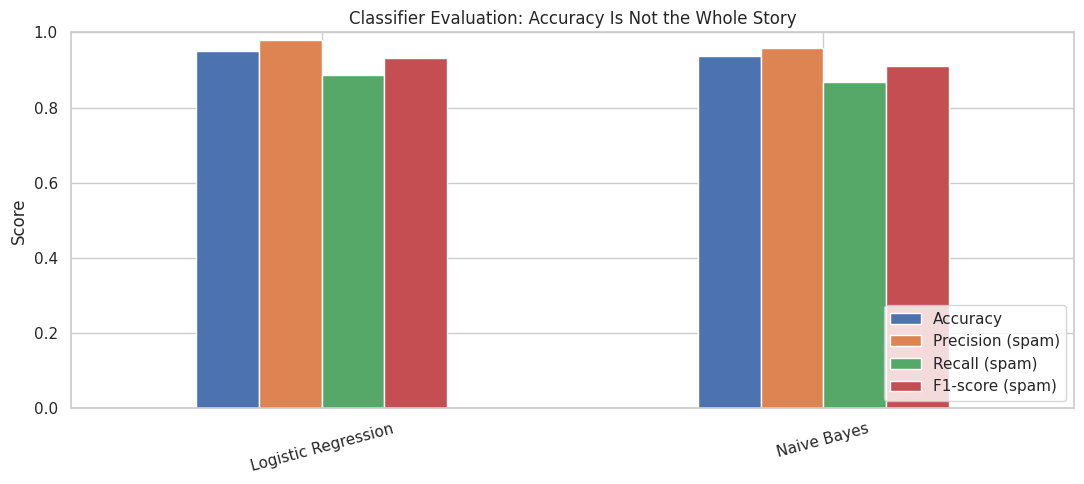

In [6]:
metrics_df.plot(kind='bar', figsize=(11, 5), ylim=(0, 1), rot=15)
plt.title('Classifier Evaluation: Accuracy Is Not the Whole Story')
plt.ylabel('Score')
plt.xlabel('')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 5. Confusion matrices

For this confusion matrix, class `0` is malignant and class `1` is benign. With `labels=[0, 1]`, the cells are ordered by those labels. The safest way to interpret the matrix is to read the actual and predicted class names on the axes.

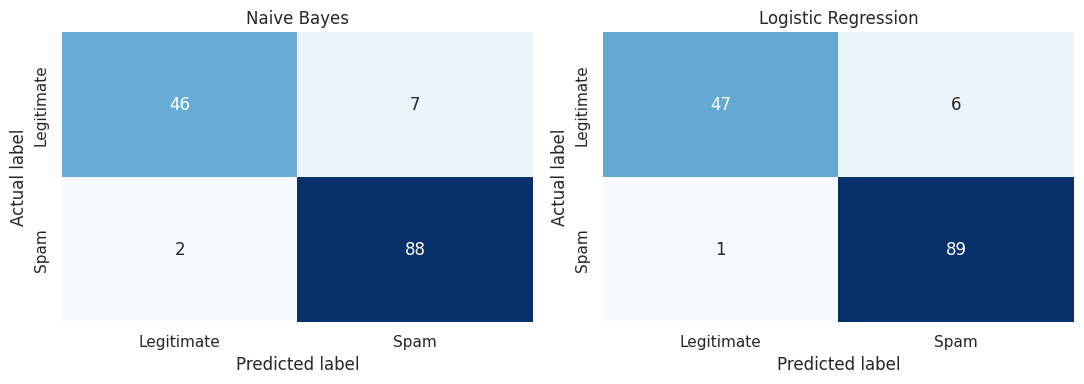

In [7]:
fig, axes = plt.subplots(1, len(predictions), figsize=(11, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Legitimate', 'Spam'], yticklabels=['Legitimate', 'Spam'])
    ax.set_title(name)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')
plt.tight_layout()
plt.show()

In [8]:
for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    print(f'\n{name}')
    print(f'TN={tn} | FP={fp} | FN={fn} | TP={tp}')
    print(f'Interpretation: the model missed {fn} spam emails and incorrectly flagged {fp} legitimate emails.')


Naive Bayes
TN=46 | FP=7 | FN=2 | TP=88
Interpretation: the model missed 2 spam emails and incorrectly flagged 7 legitimate emails.

Logistic Regression
TN=47 | FP=6 | FN=1 | TP=89
Interpretation: the model missed 1 spam emails and incorrectly flagged 6 legitimate emails.


## 6. Macro vs weighted averages (multi-class example)

Binary malignant detection has two classes. To understand averaging in a multi-class setting, this section uses three classes with unequal frequencies. **Macro** averages each class equally; **weighted** averages each class by its support (number of true examples).

In [9]:
from sklearn.datasets import make_classification

X_multi, y_multi = make_classification(
    n_samples=1800, n_features=10, n_informative=6, n_redundant=1,
    n_classes=3, n_clusters_per_class=1, weights=[0.72, 0.20, 0.08],
    class_sep=1.0, random_state=17
)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_multi, y_multi, test_size=0.25, random_state=17, stratify=y_multi
)
multi_model = LogisticRegression(max_iter=1000)
multi_model.fit(Xm_train, ym_train)
ym_pred = multi_model.predict(Xm_test)

multi_avg = pd.DataFrame({
    'Averaging method': ['Macro', 'Weighted'],
    'Precision': [precision_score(ym_test, ym_pred, average='macro', zero_division=0),
                  precision_score(ym_test, ym_pred, average='weighted', zero_division=0)],
    'Recall': [recall_score(ym_test, ym_pred, average='macro', zero_division=0),
               recall_score(ym_test, ym_pred, average='weighted', zero_division=0)],
    'F1-score': [f1_score(ym_test, ym_pred, average='macro', zero_division=0),
                 f1_score(ym_test, ym_pred, average='weighted', zero_division=0)]
}).set_index('Averaging method')
display(multi_avg.style.format('{:.3f}'))

print('\nPer-class report:')
print(classification_report(ym_test, ym_pred, zero_division=0))

,Precision,Recall,F1-score
Averaging method,,,
Macro,0.825,0.791,0.807
Weighted,0.877,0.880,0.878



Per-class report:
              precision    recall  f1-score   support

           0       0.92      0.95      0.94       322
           1       0.73      0.69      0.71        91
           2       0.82      0.73      0.77        37

    accuracy                           0.88       450
   macro avg       0.83      0.79      0.81       450
weighted avg       0.88      0.88      0.88       450



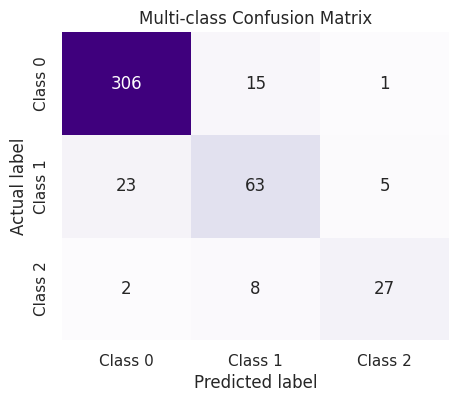

In [10]:
cm_multi = confusion_matrix(ym_test, ym_pred, labels=[0, 1, 2])
plt.figure(figsize=(5, 4))
sns.heatmap(cm_multi, annot=True, fmt='d', cmap='Purples', cbar=False,
            xticklabels=['Class 0', 'Class 1', 'Class 2'],
            yticklabels=['Class 0', 'Class 1', 'Class 2'])
plt.title('Multi-class Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.show()

## 7. Short interpretation
This summary uses the results calculated above rather than assuming a particular model will always win.

In [11]:
print('EVALUATION SUMMARY')
print('=' * 60)
best_model = metrics_df['F1-score (spam)'].idxmax()
print(f"Best model by malignant F1-score in this run: {best_model}")
print(f"Malignant prevalence in the full dataset: {100 * np.mean(y == 0):.2f}%")
print('Compare accuracy with malignant precision, recall, and F1-score before choosing a model.')
print('\nReminder: the best metric depends on the real-world cost of false positives versus false negatives.')

EVALUATION SUMMARY
Best model by malignant F1-score in this run: Logistic Regression
Malignant prevalence in the full dataset: 37.26%
Compare accuracy with malignant precision, recall, and F1-score before choosing a model.

Reminder: the best metric depends on the real-world cost of false positives versus false negatives.
